# Streaming Subscription Churn and User Engagement

**Contributors:** [Mason DeWitt]("https://github.com/madewitt55), [Elena Van]("https://github.com/3lenavan), [Prithvi Ghale]("https://github.com/PrithviGhale)

Subscription-based streaming platforms depend on recurring revenue and sustained engagement. When
activity declines, subscriptions are paused, or customers encounter billing and service problems, users
may be more likely to cancel. In this project, our team builds multiple classification model to predict
subscription churn from customer, payment, and engagement behavior. The models support targeted
retention strategies such as content discovery, service recovery, or plan adjustments.

## 1 Datasets
The data for this project is provided by Kaggle. Their [Streaming Subscription Churn Model Competiton]("https://www.kaggle.com/competitions/streaming-subscription-churn-model) provides separate training and testing datasets. The data is synthetic; it should not be used to draw conclusions about real streaming service users and their behavior. Kaggle provides this data purely for student evaluation and it should not be used to train commerical models or embedded within paid software products. The rights to this data remain restricted to the competition's context.

In [2]:
import pandas as pd

train_df = pd.read_csv("datasets/train.csv")
test_df = pd.read_csv("datasets/test.csv")

print(f"Train: {train_df.shape}")
print(f"Test: {test_df.shape}")

Train: (125000, 20)
Test: (75000, 19)


The training data set consists of **125,000 records** and **20 variables**. The testing set consists of **75,000 records** and **19 variables** (the target variable is excluded from the testing set).

## 2 Data Quality Analysis

### 2.1 Variables

Kaggle's datasets provide 20 total variables along with descriptive documentation defining units wherever necessary.

#### 2.1.1 Identifiers
- `customer_id` - A unique customer identification number

Indentifiers provide no real description of the customer and <mark>are excluded from modeling.</mark>

#### 2.1.2 Categorical Predictors

In [16]:
# Text (object) columns hold categorical labels
categorical_predictors = list(train_df.select_dtypes(include="object").columns)
print(f"Categorical predictors ({len(categorical_predictors)}): {categorical_predictors}")

Categorical predictors (5): ['location', 'subscription_type', 'payment_plan', 'payment_method', 'customer_service_inquiries']


- `location` - The US state of the user
- `subscription_type` - Type of subscription
- `payment_plan` - How often the user pays, monthly or annually
- `payment_method` - Form of user payment
- `customer_service_inquiries` - The frequency of customer service inquiries from the user

Categorical predictors hold a non-numerical value and must be encoded before modeling.

#### 2.1.3 Numerical Predictors

In [15]:
# Numeric columns other than the identifier and target hold numerical predictors
numerical_predictors = [
    col for col in train_df.select_dtypes(include="number").columns
    if col not in ("customer_id", "churned")
]
print(f"Numerical predictors ({len(numerical_predictors)}): {numerical_predictors}")

Numerical predictors (13): ['age', 'num_subscription_pauses', 'signup_date', 'weekly_hours', 'average_session_length', 'song_skip_rate', 'weekly_songs_played', 'weekly_unique_songs', 'num_favorite_artists', 'num_platform_friends', 'num_playlists_created', 'num_shared_playlists', 'notifications_clicked']


- `age` - The age of the user
- `num_subscription_pauses` - Number of times the user has paused their subscription (max 2)
- `signup_date` - Date the user signed up for the music subscription service
- `weekly_hours` - Average number of weekly listening hours
- `average_session_length` - Average length of each music listening session (in hours)
- `song_skip_rate` - Percentage of songs the user does not finish
- `weekly_songs_played` - Average number of songs the user plays in a week
- `weekly_unique_songs` - Average number of unique songs the user plays in a week
- `num_favorite_artists` - Number of artists the user set as favorite artists
- `num_platform_friends` - Number of user connections in the app
- `num_playlists_created` - Number of playlists the user created
- `num_shared_playlists` - Number of playlists that are shared publicly
- `notifications_clicked` - Number of in-app notifications clicked on

Numerical predictors hold a numerical value and do not require encoding before modeling.

#### 2.1.4 Target
- `churned` - Whether the customer is active or churned
    - Positive class (1): Customer is **churned**
    - Negative class (0): Customer is **active**

The target variable is the customer's attribute to be predicted. We aim to classify a customer as either churned or active.

### 2.2 Duplicate Identifiers

In [17]:
duplicate_check = pd.DataFrame({
    "duplicate_customer_ids": [
        train_df["customer_id"].duplicated().sum(),
        test_df["customer_id"].duplicated().sum(),
    ],
    "ids_shared_with_other_set": [
        train_df["customer_id"].isin(test_df["customer_id"]).sum(),
        test_df["customer_id"].isin(train_df["customer_id"]).sum(),
    ],
}, index=["train", "test"])
display(duplicate_check)

,duplicate_customer_ids,ids_shared_with_other_set
train,0,0
test,0,0


Neither the training nor testing set include duplicate values for a customer's unique identifier. No unique identifier is present in both sets. <mark>No identifiers need to be removed or reassigned.</mark>

### 2.3 Missing Values

In [4]:
# Count nulls plus empty or whitespace-only strings per column
def count_missing(df):
    blanks = df.select_dtypes("object").apply(lambda s: s.str.strip() == "").sum()
    return df.isna().sum().add(blanks, fill_value=0)


missing_values = pd.DataFrame({
    "train": count_missing(train_df),
    "test": count_missing(test_df),
}).astype("Int64")
display(missing_values)
print(f"Total missing - train: {missing_values['train'].sum()}, test: {missing_values['test'].sum()}")

,train,test
age,0,0
average_session_length,0,0
churned,0,<NA>
customer_id,0,0
customer_service_inquiries,0,0
location,0,0
notifications_clicked,0,0
num_favorite_artists,0,0
num_platform_friends,0,0
num_playlists_created,0,0


Total missing - train: 0, test: 0


Neither the training nor testing set include rows with missing variable values. <mark>No imputation or row removal is needed.</mark>

### 2.4 Plausible Value Constraints

Plausible ranges are set from domain knowledge and documentation provided by Kaggle, not from the observed data.

| Variable | Plausible range | Rationale |
|---|---|---|
| `customer_id` | Integer >= 1 | Positive identifier |
| `age` | 13 to 100 | Typical minimum age for a streaming account |
| `num_subscription_pauses` | 0 to 2 | Documented maximum of 2 |
| `signup_date` | -3650 to 0 | Days relative to a reference date, up to 10 years back, never in the future |
| `weekly_hours` | 0 to 168 | Hours in a week |
| `average_session_length` | 0 to 24 | 24 hour max listening session |
| `song_skip_rate` | 0 to 1 | Stored as a proportion |
| `weekly_songs_played` | 0 to 3500 | About 20 songs per hour over 168 hours |
| `weekly_unique_songs` | 0 to 3500, and <= `weekly_songs_played` | Cannot play more unique songs than total songs |
| `num_favorite_artists` | 0 to 1000 | Non-negative count with a generous cap |
| `num_platform_friends` | 0 to 5000 | Non-negative count with a generous cap |
| `num_playlists_created` | 0 to 1000 | Non-negative count with a generous cap |
| `num_shared_playlists` | 0 to 1000 | Non-negative count with a generous cap |
| `notifications_clicked` | 0 to 1000 | Non-negative count with a generous cap |
| `churned` | 0 or 1 | Binary target |
| `location` | One of the 50 US states | Spelled correctly |
| `subscription_type` | Free, Premium, Student, Family | Known plan types |
| `payment_plan` | Monthly, Yearly | Known billing options |
| `payment_method` | Credit Card, Debit Card, Paypal, Apple Pay | Known payment methods |
| `customer_service_inquiries` | Low, Medium, High | Known frequency levels |

In [5]:
numeric_ranges = {
    "age": (13, 100),
    "num_subscription_pauses": (0, 2),
    "signup_date": (-3650, 0),
    "weekly_hours": (0, 168),
    "average_session_length": (0, 24),
    "song_skip_rate": (0, 1),
    "weekly_songs_played": (0, 3500),
    "weekly_unique_songs": (0, 3500),
    "num_favorite_artists": (0, 1000),
    "num_platform_friends": (0, 5000),
    "num_playlists_created": (0, 1000),
    "num_shared_playlists": (0, 1000),
    "notifications_clicked": (0, 1000),
}

allowed_categories = {
    "location": {
        "Alabama", "Alaska", "Arizona", "Arkansas", "California", "Colorado", "Connecticut",
        "Delaware", "Florida", "Georgia", "Hawaii", "Idaho", "Illinois", "Indiana", "Iowa",
        "Kansas", "Kentucky", "Louisiana", "Maine", "Maryland", "Massachusetts", "Michigan",
        "Minnesota", "Mississippi", "Missouri", "Montana", "Nebraska", "Nevada", "New Hampshire",
        "New Jersey", "New Mexico", "New York", "North Carolina", "North Dakota", "Ohio",
        "Oklahoma", "Oregon", "Pennsylvania", "Rhode Island", "South Carolina", "South Dakota",
        "Tennessee", "Texas", "Utah", "Vermont", "Virginia", "Washington", "West Virginia",
        "Wisconsin", "Wyoming",
    },
    "subscription_type": {"Free", "Premium", "Student", "Family"},
    "payment_plan": {"Monthly", "Yearly"},
    "payment_method": {"Credit Card", "Debit Card", "Paypal", "Apple Pay"},
    "customer_service_inquiries": {"Low", "Medium", "High"},
}

# Count rows outside the plausible range for each variable
def count_violations(df):
    counts = {"customer_id": int((df["customer_id"] < 1).sum())}
    for col, (low, high) in numeric_ranges.items():
        counts[col] = int((~df[col].between(low, high)).sum())
    for col, allowed in allowed_categories.items():
        counts[col] = int((~df[col].isin(allowed)).sum())
    if "churned" in df:
        counts["churned"] = int((~df["churned"].isin([0, 1])).sum())
    counts["weekly_unique_songs > weekly_songs_played"] = int(
        (df["weekly_unique_songs"] > df["weekly_songs_played"]).sum()
    )
    return pd.Series(counts)


range_violations = pd.DataFrame({
    "train": count_violations(train_df),
    "test": count_violations(test_df),
}).astype("Int64")  # test has no churned column (<NA>)
display(range_violations)

all_in_range = (range_violations.fillna(0) == 0).all().all()
print(f"All values plausible: {all_in_range}")

,train,test
age,0,0
average_session_length,100768,60497
churned,0,<NA>
customer_id,0,0
customer_service_inquiries,0,0
location,6601,4026
notifications_clicked,0,0
num_favorite_artists,0,0
num_platform_friends,0,0
num_playlists_created,0,0


All values plausible: False


#### 2.4.1 Session Length Anomalies

The plausible value check saw *161,265* total out-of-range values for numerical predictor `average_session_length`. Kaggle's documentation of these datasets defines the units as hours.

In [6]:
session_min, session_max = numeric_ranges["average_session_length"]

session_summary = pd.DataFrame({
    "observed_min": [df["average_session_length"].min() for df in (train_df, test_df)],
    "observed_max": [df["average_session_length"].max() for df in (train_df, test_df)],
    "pct_above_range": [(df["average_session_length"] > session_max).mean() * 100 for df in (train_df, test_df)],
    "pct_below_range": [(df["average_session_length"] < session_min).mean() * 100 for df in (train_df, test_df)],
}, index=["train", "test"])
session_summary.insert(0, "plausible_range", f"{session_min} to {session_max}")
display(session_summary.round(2))

,plausible_range,observed_min,observed_max,pct_above_range,pct_below_range
train,0 to 24,1.0,120.0,80.61,0.0
test,0 to 24,1.0,120.0,80.66,0.0


The observed maximum of this variable in both the training and testing sets is *120.* With the units as hours (defined by Kaggle), this represents 5 straight days of listening. With the units as minutes, this represents 2 hours of listening (much more sensible). Since over 80% of all rows hold a value greater than 24 for `average_session_length`, it is highly likely that variable's units were intended to be documented as minutes. <mark>We will adjust our units and plausible value range accordingly.</mark> 

#### 2.4.2 Location Anomalies

The plausible value check saw *10,627* total invalid values for categorical predictor `location`. Kaggle's documentation of the data states this variable should hold a string value of a valid US state.

In [7]:
import difflib

valid_states = allowed_categories["location"]

location_counts = pd.DataFrame({
    "train": train_df["location"].value_counts(),
    "test": test_df["location"].value_counts(),
}).fillna(0).astype(int)
location_counts["total"] = location_counts["train"] + location_counts["test"]
location_counts["valid_state"] = location_counts.index.isin(valid_states)

# for each invalid label, find the closest valid state and check whether that state appears in the data
invalid_locations = location_counts[~location_counts["valid_state"]].copy()
invalid_locations["closest_valid_state"] = [
    next(iter(difflib.get_close_matches(loc, valid_states, n=1, cutoff=0.8)), None)
    for loc in invalid_locations.index
]
display(invalid_locations)

,train,test,total,valid_state,closest_valid_state
location,,,,,
Nebrasksa,6601,4026,10627,False,Nebraska


In [8]:
# "Nebrasksa" is the only invalid location and has no correctly spelled counterpart in the data,
# so it is treated as a misspelling of Nebraska. Only the dataframes are changed, not the CSVs.
for name, df in (("train", train_df), ("test", test_df)):
    typo_rows = (df["location"] == "Nebrasksa").sum()
    df["location"] = df["location"].replace("Nebrasksa", "Nebraska")
    print(f"{name}: corrected {typo_rows} rows, invalid locations remaining: "
          f"{(~df['location'].isin(valid_states)).sum()}")

train: corrected 6601 rows, invalid locations remaining: 0
test: corrected 4026 rows, invalid locations remaining: 0


The only non-valid location the appears in both the training and testing sets is *"Nebrasksa."* It is highly likely that this is simply a frequent typo meant to represent the actual valid US state *Nebraska*. <mark>We will modify these rows to hold the correct and intended state.</mark>

#### 2.4.3 Subscription Pauses Anomaly
The plausible value check saw *49,694* out-of-range values for numerical predictor `num_subscriptions_pauses`. Kaggle's documentation of these datasets defines the maximum value as 2.

In [9]:
pause_min, pause_max = numeric_ranges["num_subscription_pauses"]

pause_summary = pd.DataFrame({
    "observed_min": [df["num_subscription_pauses"].min() for df in (train_df, test_df)],
    "observed_max": [df["num_subscription_pauses"].max() for df in (train_df, test_df)],
    "pct_above_max": [(df["num_subscription_pauses"] > pause_max).mean() * 100 for df in (train_df, test_df)],
    "pct_below_min": [(df["num_subscription_pauses"] < pause_min).mean() * 100 for df in (train_df, test_df)],
}, index=["train", "test"])
pause_summary.insert(0, "documented_range", f"{pause_min} to {pause_max}")
display(pause_summary.round(2))

,documented_range,observed_min,observed_max,pct_above_max,pct_below_min
train,0 to 2,0,4,39.76,0.0
test,0 to 2,0,4,39.79,0.0


Nearly 40% of rows in both the training and testing sets hold more than 2 subscription pauses, with an observed maximum of 4. This is far too common to be data entry error, so the documented maximum of 2 appears to be inaccurate. <mark>We will update the plausible range to 0 to 4 subscription pauses.</mark>

#### 2.4.4 Weekly Unique Songs vs Weekly Total Songs Anomalies

The plausible value check saw *59,424* invalid values for numerical predictor `weekly_unique_songs`. Kaggle's documentation of these datasets defines this variable as the average number of unique songs a user plays in a week, which cannot exceed the total number of songs played (`weekly_songs_played`). We came up with two potential options for correcting this.

##### Option 1: kNN Imputation

Rows where `weekly_unique_songs` exceeds `weekly_songs_played` could have one of the two values marked as missing and replaced with the average value of the most similar customers, as measured by their other predictors. Either variable could be imputed, since it is not known which of the two is wrong. This only works if the other predictors carry information about the variable being imputed.

In [10]:
song_cols = ["weekly_unique_songs", "weekly_songs_played"]

song_corr = train_df[list(numeric_ranges)].corr()[song_cols]

# order predictors by their strongest correlation with another variable (self-correlation of 1 excluded)
off_diagonal = song_corr.copy()
for col in song_cols:
    off_diagonal.loc[col, col] = float("nan")
song_corr = song_corr.loc[off_diagonal.abs().max(axis=1).sort_values(ascending=False).index]
display(song_corr.add_prefix("corr_with_").round(3))

,corr_with_weekly_unique_songs,corr_with_weekly_songs_played
num_favorite_artists,0.005,0.005
average_session_length,-0.005,-0.000
num_platform_friends,-0.001,0.003
song_skip_rate,0.001,-0.003
notifications_clicked,0.003,-0.003
signup_date,0.000,0.003
num_subscription_pauses,-0.003,-0.001
num_playlists_created,0.000,-0.002
num_shared_playlists,-0.000,0.002
age,-0.001,-0.002


The Linear (Pearson) correlations between `weekly_unique_songs` and `weekly_songs_played` (total songs) and the rest of the numerical predictors are extremely weak. This indicates that the other predictors contribute very little, if not nothing, to the value of the two potential targets for kNN imputation. While kNN can capture non-linear relationships, these linear correlations are practically negligible. <mark>kNN imputation will very likely fail at accurately predicting invalid `weekly_unique_songs` or `weekly_songs_played` values.</mark>

#### Option 2: Imposing a Cap on Weekly Unique Songs

Rows where `weeky_unique_songs` exceeds `weekly_songs_played` could reduced to the exact value as `weekly_songs_played`. This would make their `weekly_unique_songs` value plausible and is not restricted by weak linear relationships. <mark>We have selected this option to correct the inplausibilities.</mark>

In [11]:
# Cap weekly_unique_songs at weekly_songs_played on rows where it exceeds it. Only the dataframes are changed, not the CSVs.
for name, df in (("Train", train_df), ("Test", test_df)):
    exceeds = df["weekly_unique_songs"] > df["weekly_songs_played"]
    df.loc[exceeds, "weekly_unique_songs"] = df.loc[exceeds, "weekly_songs_played"]
    print(f"{name}: capped {exceeds.sum()} rows, rows still exceeding: "
          f"{(df['weekly_unique_songs'] > df['weekly_songs_played']).sum()}")

Train: capped 36996 rows, rows still exceeding: 0
Test: capped 22428 rows, rows still exceeding: 0


### 2.6 Updated Plausible Value Restrictions

| Variable | Plausible range | Rationale |
|---|---|---|
| `customer_id` | Integer >= 1 | Positive identifier |
| `age` | 13 to 100 | Typical minimum age for a streaming account |
| `num_subscription_pauses` | 0 to 4 | Maximum 4 subscription pauses **(updated from documented maximum of 2)** |
| `signup_date` | -3650 to 0 | Days relative to a reference date, up to 10 years back, never in the future |
| `weekly_hours` | 0 to 168 | Hours in a week |
| `average_session_length` | 0 to 1440 | 1440 minute max listening session **(updated from documented units of hours)** |
| `song_skip_rate` | 0 to 1 | Stored as a proportion |
| `weekly_songs_played` | 0 to 3500 | About 20 songs per hour over 168 hours |
| `weekly_unique_songs` | 0 to 3500, and <= `weekly_songs_played` | Cannot play more unique songs than total songs |
| `num_favorite_artists` | 0 to 1000 | Non-negative count with a generous cap |
| `num_platform_friends` | 0 to 5000 | Non-negative count with a generous cap |
| `num_playlists_created` | 0 to 1000 | Non-negative count with a generous cap |
| `num_shared_playlists` | 0 to 1000 | Non-negative count with a generous cap |
| `notifications_clicked` | 0 to 1000 | Non-negative count with a generous cap |
| `churned` | 0 or 1 | Binary target |
| `location` | One of the 50 US states | Spelled correctly |
| `subscription_type` | Free, Premium, Student, Family | Known plan types |
| `payment_plan` | Monthly, Yearly | Known billing options |
| `payment_method` | Credit Card, Debit Card, Paypal, Apple Pay | Known payment methods |
| `customer_service_inquiries` | Low, Medium, High | Known frequency levels |

`location` values of misspelled state names such as "Nebrasksa" have been corrected. `weekly_unique_songs` values that exceed the value of `weekly_songs_played` in the same row have been capped to the value of `weekly_songs_played`.

In [12]:
numeric_ranges = {
    "age": (13, 100),
    "num_subscription_pauses": (0, 4),
    "signup_date": (-3650, 0),
    "weekly_hours": (0, 168),
    "average_session_length": (0, 1440),
    "song_skip_rate": (0, 1),
    "weekly_songs_played": (0, 3500),
    "weekly_unique_songs": (0, 3500),
    "num_favorite_artists": (0, 1000),
    "num_platform_friends": (0, 5000),
    "num_playlists_created": (0, 1000),
    "num_shared_playlists": (0, 1000),
    "notifications_clicked": (0, 1000),
}

allowed_categories = {
    "location": {
        "Alabama", "Alaska", "Arizona", "Arkansas", "California", "Colorado", "Connecticut",
        "Delaware", "Florida", "Georgia", "Hawaii", "Idaho", "Illinois", "Indiana", "Iowa",
        "Kansas", "Kentucky", "Louisiana", "Maine", "Maryland", "Massachusetts", "Michigan",
        "Minnesota", "Mississippi", "Missouri", "Montana", "Nebraska", "Nevada", "New Hampshire",
        "New Jersey", "New Mexico", "New York", "North Carolina", "North Dakota", "Ohio",
        "Oklahoma", "Oregon", "Pennsylvania", "Rhode Island", "South Carolina", "South Dakota",
        "Tennessee", "Texas", "Utah", "Vermont", "Virginia", "Washington", "West Virginia",
        "Wisconsin", "Wyoming",
    },
    "subscription_type": {"Free", "Premium", "Student", "Family"},
    "payment_plan": {"Monthly", "Yearly"},
    "payment_method": {"Credit Card", "Debit Card", "Paypal", "Apple Pay"},
    "customer_service_inquiries": {"Low", "Medium", "High"},
}

# Count rows outside the plausible range for each variable
def count_violations(df):
    counts = {"customer_id": int((df["customer_id"] < 1).sum())}
    for col, (low, high) in numeric_ranges.items():
        counts[col] = int((~df[col].between(low, high)).sum())
    for col, allowed in allowed_categories.items():
        counts[col] = int((~df[col].isin(allowed)).sum())
    if "churned" in df:
        counts["churned"] = int((~df["churned"].isin([0, 1])).sum())
    counts["weekly_unique_songs > weekly_songs_played"] = int(
        (df["weekly_unique_songs"] > df["weekly_songs_played"]).sum()
    )
    return pd.Series(counts)


range_violations = pd.DataFrame({
    "train": count_violations(train_df),
    "test": count_violations(test_df),
}).astype("Int64")  # test has no churned column (<NA>)
display(range_violations)

all_in_range = (range_violations.fillna(0) == 0).all().all()
print(f"All values plausible: {all_in_range}")

,train,test
age,0,0
average_session_length,0,0
churned,0,<NA>
customer_id,0,0
customer_service_inquiries,0,0
location,0,0
notifications_clicked,0,0
num_favorite_artists,0,0
num_platform_friends,0,0
num_playlists_created,0,0


All values plausible: True


After updating plausible value restrictions and cleaning invalid data, <mark>all *125,000* rows of the training set and *75,000* rows of the testing set pass plausible value validation.</mark>

### 2.7 Target Class Proportions

In classification, the proportion of each class matters. An imbalanced dataset where one class dominates can cause the model to almost always choose the majority class. We check class balance for the entire dataset as well as the training and testing data separately.

In [13]:
print("Overall class proportions (training set):\n")
counts_all = train_df["churned"].value_counts().sort_index()
props_all  = train_df["churned"].value_counts(normalize=True).sort_index()
for label in [0, 1]:
    label_str = "Not churned (0)" if label == 0 else "Churned (1)"
    print(f"  Risk={label}  {label_str}:  {counts_all[label]:4d}  ({props_all[label]:.1%})")

Overall class proportions (training set):

  Risk=0  Not churned (0):  60826  (48.7%)
  Risk=1  Churned (1):  64174  (51.3%)


The training set rows are 48.7% `churned = 0` and 51.3% `churned = 1`. <mark>This is a tiny proportion difference and should not be treated as an issue.</mark>

### 2.8 Outlier Detection

Outliers are detected on the numerical predictors using the **interquartile range (IQR).** With Q1 and Q3 as the 25th and 75th percentiles, `IQR = Q3 - Q1`. Values below the **lower fence** (Q1 - 1.5 × IQR) or above the **upper fence** (Q3 + 1.5 × IQR) are flagged as outliers. Fences are computed separately for the training and testing sets.

In [24]:
# Summarize the IQR fences and the number of values outside them for each numerical predictor
def iqr_outlier_summary(df):
    q1 = df[numerical_predictors].quantile(0.25)
    q3 = df[numerical_predictors].quantile(0.75)
    iqr = q3 - q1
    lower_fence = q1 - 1.5 * iqr
    upper_fence = q3 + 1.5 * iqr
    outliers = (df[numerical_predictors].lt(lower_fence) | df[numerical_predictors].gt(upper_fence)).sum()
    return pd.DataFrame({
        "median": df[numerical_predictors].median(),
        "Q1": q1,
        "Q3": q3,
        "lower_fence": lower_fence,
        "upper_fence": upper_fence,
        "outliers": outliers,
    })


train_outliers = iqr_outlier_summary(train_df)
test_outliers = iqr_outlier_summary(test_df)

print("Training set")
display(train_outliers.round(2))
print(f"Total outliers flagged: {train_outliers['outliers'].sum()}")

print("\nTesting set")
display(test_outliers.round(2))
print(f"Total outliers flagged: {test_outliers['outliers'].sum()}")

Training set


,median,Q1,Q3,lower_fence,upper_fence,outliers
age,48.00,33.00,64.00,-13.50,110.50,0
num_subscription_pauses,2.00,1.00,3.00,-2.00,6.00,0
signup_date,-1462.00,-2190.00,-728.00,-4383.00,1465.00,0
weekly_hours,25.12,12.47,37.57,-25.17,75.22,0
average_session_length,60.34,30.64,90.23,-58.74,179.62,0
song_skip_rate,0.50,0.25,0.75,-0.50,1.50,0
weekly_songs_played,251.00,127.00,375.00,-245.00,747.00,0
weekly_unique_songs,110.00,52.00,182.00,-143.00,377.00,0
num_favorite_artists,25.00,12.00,37.00,-25.50,74.50,0
num_platform_friends,100.00,50.00,150.00,-100.00,300.00,0


Total outliers flagged: 0

Testing set


,median,Q1,Q3,lower_fence,upper_fence,outliers
age,48.00,33.00,64.00,-13.50,110.50,0
num_subscription_pauses,2.00,1.00,3.00,-2.00,6.00,0
signup_date,-1458.00,-2199.00,-729.00,-4404.00,1476.00,0
weekly_hours,24.81,12.30,37.44,-25.40,75.14,0
average_session_length,60.68,30.75,90.29,-58.55,179.59,0
song_skip_rate,0.50,0.25,0.75,-0.50,1.50,0
weekly_songs_played,251.00,127.00,374.00,-243.50,744.50,0
weekly_unique_songs,111.00,53.00,184.00,-143.50,380.50,0
num_favorite_artists,24.00,12.00,37.00,-25.50,74.50,0
num_platform_friends,99.00,49.00,149.00,-101.00,299.00,0


Total outliers flagged: 0


The IQR method flags no outliers in either the training or testing set. Every value of every numerical predictor falls within its fences. <mark>No rows need to be removed or adjusted for outliers.</mark>

### 2.9 Parse Date Fields

Date fields must be converted to a numerical representation before modeling. `signup_date` is the only date field in the datasets.

#### 2.9.1 Signup Date

We check whether `signup_date` needs parsing by inspecting its data type and values.

In [20]:
signup_summary = pd.DataFrame({
    "dtype": [str(df["signup_date"].dtype) for df in (train_df, test_df)],
    "min": [df["signup_date"].min() for df in (train_df, test_df)],
    "max": [df["signup_date"].max() for df in (train_df, test_df)]
}, index=["train", "test"])
display(signup_summary)

,dtype,min,max
train,int64,-2922,-1
test,int64,-2922,-1


`signup_date` is already stored as an integer number of days relative to the date the data was recorded (-2922 to -1, signups cannot be recorded after the data was recorded). Because the values are negative, a more negative value means an older account (longer tenure). This only flips the sign of the relationship, so it does not affect modeling. <mark>`signup_date` requires no parsing and is used as is.</mark>

### 2.10 Train vs Test Distribution

Models are fit on the training set and applied to the testing set, so the two should come from the same population. We use a two-sample **Kolmogorov-Smirnov (KS) test** on each numerical predictor. We use a significance threshold (`ALPHA`) of *0.05* per convention and a stricter secondary signifigance threshold (`bonferroni_alpha`) of *0.004* (`ALPHA` / number of predictors tested).

For each numerical predictor, the hypotheses are:
- **Null hypothesis (H₀):** The predictor's values in the training and testing sets are sampled from the **same population.**
- **Alternative hypothesis (H₁):** The predictor's values in the training and testing sets are sampled from **different populations.**

We reject H₀ for a predictor only if its p-value falls below the significance level.

In [37]:
from scipy import stats

ALPHA = 0.05
bonferroni_alpha = ALPHA / len(numerical_predictors)  # correct for running one test per predictor

ks_tests = [stats.ks_2samp(train_df[col], test_df[col]) for col in numerical_predictors]
ks_results = pd.DataFrame({
    "ks_statistic": [test.statistic for test in ks_tests],
    "p_value": [test.pvalue for test in ks_tests],
}, index=numerical_predictors)
ks_results["significant_at_0.05"] = ks_results["p_value"] < ALPHA
ks_results["significant_bonferroni"] = ks_results["p_value"] < bonferroni_alpha
display(ks_results.sort_values("ks_statistic", ascending=False).round(4))
print(f"Bonferroni-corrected significance level: {bonferroni_alpha:.4f}")

,ks_statistic,p_value,significant_at_0.05,significant_bonferroni
weekly_unique_songs,0.0070,0.0196,True,False
weekly_hours,0.0070,0.0198,True,False
num_shared_playlists,0.0058,0.0886,False,False
notifications_clicked,0.0051,0.1680,False,False
num_playlists_created,0.0045,0.2856,False,False
age,0.0044,0.3115,False,False
num_platform_friends,0.0041,0.4242,False,False
average_session_length,0.0038,0.4973,False,False
num_favorite_artists,0.0037,0.5341,False,False
signup_date,0.0035,0.6191,False,False


Bonferroni-corrected significance level: 0.0038


The KS test produces cumulative distribution curves for both the train and test set for each predictor. On these curves, the x-axis is the value of the predictor and y-axis is the fraction of values in the dataset that are lesser than or equal to x.

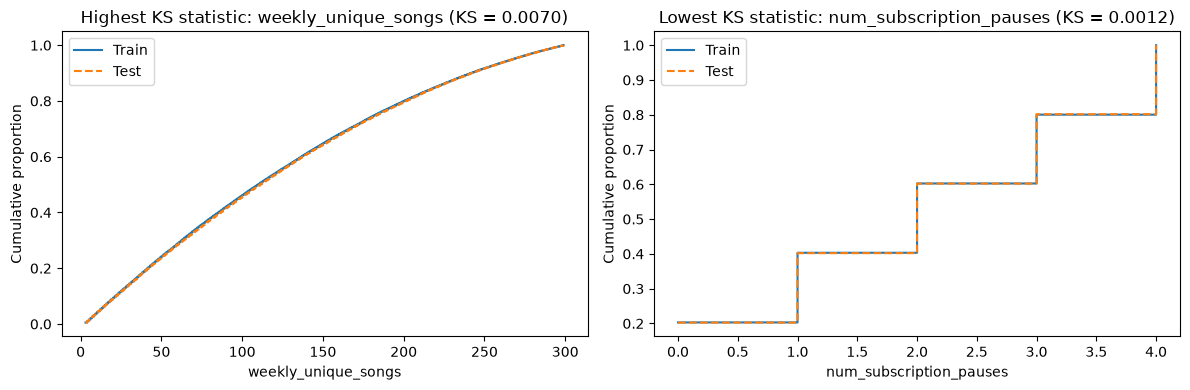

In [ ]:
import matplotlib.pyplot as plt
import numpy as np


def ecdf(values, grid):
    """Fraction of values at or below each point of the grid."""
    return np.searchsorted(np.sort(values), grid, side="right") / len(values)

extreme_predictors = {
    "Highest KS statistic": ks_results["ks_statistic"].idxmax(),
    "Lowest KS statistic": ks_results["ks_statistic"].idxmin(),
}

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for (label, col), ax in zip(extreme_predictors.items(), axes):
    grid = np.sort(np.concatenate([train_df[col], test_df[col]]))

    ax.step(grid, ecdf(train_df[col], grid), where="post", label="Train")
    ax.step(grid, ecdf(test_df[col], grid), where="post", label="Test", linestyle="--")
    ax.set_title(f"{label}: {col} (KS = {ks_results.loc[col, 'ks_statistic']:.4f})")
    ax.set_xlabel(col)
    ax.set_ylabel("Cumulative proportion")
    ax.legend()

plt.tight_layout()
plt.show()

- **`ks_statistic`** - The largest gap between the training and testing cumulative distributions, from 0 (identical) to 1 (completely separate); measures how big the difference is.
- **`p_value`** - The probability of seeing a gap at least this large when random sampling from the sample population; distinguishes a population shift from noise.
- **signifcant_at_0.05** - Whether the p-value is below the defined *0.05* threshold; determines whether a predictor's distribution is suspicious.
- **`significant_bonferroni`** - Whether the p-value is below the stricter threshold of 0.05 divided by the 13 tests run (about *0.004*); guards against expected false positives from large datasets.

Every numerical predictor has a KS statistic of *0.007* or less, meaning the training and testing distributions are nearly identical. `weekly_unique_songs` and `weekly_hours` have p-values slightly under our chosen alpha of *0.05* (about *0.02*). With 13 tests, we expect roughly one false positive by chance, and neither survives the Bonferroni correction (significance level of about *0.004*). <mark>The numerical predictors frim the training and testing sets indicate they were sampled from the same population. We fail to reject the null hypothesis for every numerical predictor.</mark>

### 2.11 Predictor vs Predictor Correlation

Strongly correlated predictors carry redundant information. This can destabilize the coefficients of logistic regression and overweight the shared signal in distance-based models like kNN. We compute pairwise Pearson correlations between the numerical predictors of the training set (the data the models are fit on) and flag any pair with an absolute correlation of 0.7 or higher. Categorical predictors are excluded because their encoding is deferred.

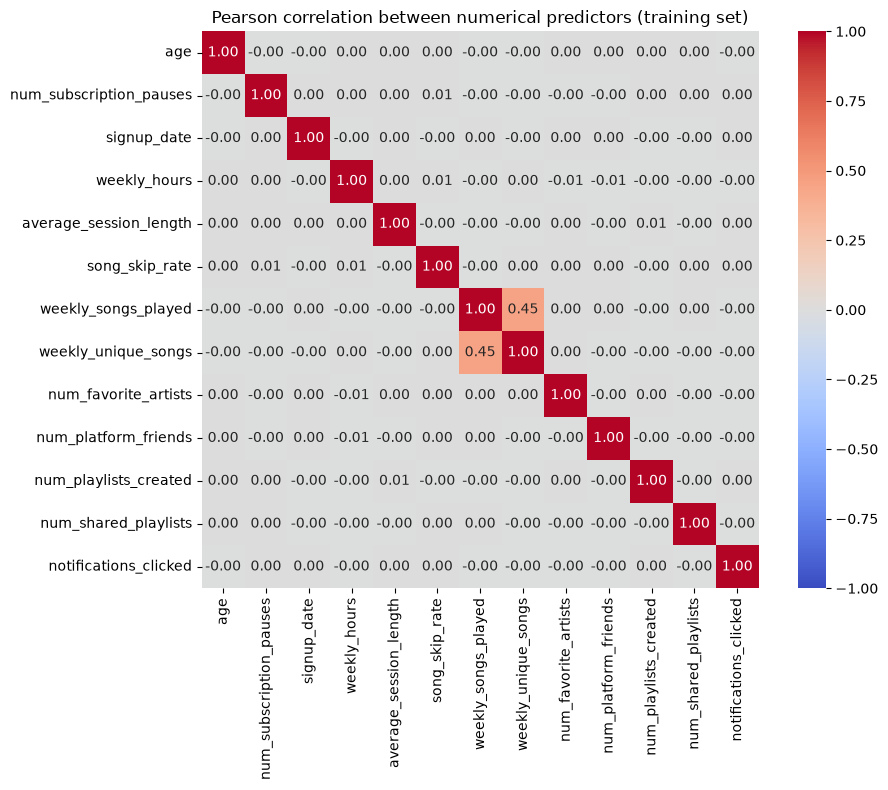

In [25]:
import matplotlib.pyplot as plt
import seaborn as sns

corr_matrix = train_df[numerical_predictors].corr()

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True, ax=ax)
ax.set_title("Pearson correlation between numerical predictors (training set)")
plt.tight_layout()
plt.show()

Almost all predictor pairs have an extremely weak linear correlation. This indicates that there is no **multicollinearity** within the dataset. A mild linear correlation strength of `0.45` was observed between `weekly_songs_played` and `weekly_unique_songs`. Before applying the cap to `weekly_unique_songs`, we observed a neglible `0.001` correlation between the two predictors. Applying this cap resulted in tens of thousands of rows holding the exact same value for these two predictors, making our observation of a substanstial increase in correlation strength expected. Nonetheless, a `0.45` correlation strength is not considered to be extreme and <mark>no predictor needs to be excluded from modeling.</mark>

### 2.12 Predictor Class Distribution

A predictor is only useful if its distribution differs between customers who churned and those who did not. We compare each predictor across the two target classes in the training set (the only set with labels). For numerical predictors we compare the median of each class, the point-biserial correlation with `churned`, and the p-value of a Mann-Whitney U test. For categorical predictors we compare the churn rate across categories and test for independence with a chi-squared test.

In [27]:
from scipy import stats

active = train_df[train_df["churned"] == 0]
churned = train_df[train_df["churned"] == 1]

numerical_vs_target = pd.DataFrame({
    "median_active": active[numerical_predictors].median(),
    "median_churned": churned[numerical_predictors].median(),
    "correlation_with_churned": [train_df[col].corr(train_df["churned"]) for col in numerical_predictors],
    "mann_whitney_p": [stats.mannwhitneyu(active[col], churned[col]).pvalue for col in numerical_predictors],
})
numerical_vs_target = numerical_vs_target.reindex(
    numerical_vs_target["correlation_with_churned"].abs().sort_values(ascending=False).index
)
display(numerical_vs_target.round(4))

,median_active,median_churned,correlation_with_churned,mann_whitney_p
weekly_hours,30.4499,19.7133,-0.3025,0.0000
num_subscription_pauses,2.0000,3.0000,0.1830,0.0000
song_skip_rate,0.4404,0.5746,0.1602,0.0000
age,47.0000,50.0000,0.0487,0.0000
notifications_clicked,25.0000,24.0000,-0.0424,0.0000
weekly_unique_songs,108.0000,112.0000,0.0138,0.0000
average_session_length,60.5951,60.0831,-0.0065,0.0214
num_favorite_artists,25.0000,24.0000,-0.0054,0.0572
num_shared_playlists,24.0000,25.0000,0.0038,0.1753
num_platform_friends,100.0000,100.0000,-0.0030,0.2920


Three numerical predictors show a meaningful relationship with churn: `weekly_hours` (churned customers listen less, correlation of about -0.30), `num_subscription_pauses` (churned customers pause more, about 0.18), and `song_skip_rate` (churned customers skip more, about 0.16). `age` and `notifications_clicked` have statistically significant but very weak relationships (about 0.05 and -0.04). The remaining predictors have correlations near zero, so their distributions are nearly identical between the two classes.

In [28]:
categorical_vs_target = []
for col in categorical_predictors:
    churn_rate = train_df.groupby(col)["churned"].mean()
    chi2_p = stats.chi2_contingency(pd.crosstab(train_df[col], train_df["churned"]))[1]
    categorical_vs_target.append({
        "predictor": col,
        "categories": len(churn_rate),
        "lowest_churn_rate": churn_rate.min(),
        "highest_churn_rate": churn_rate.max(),
        "chi2_p": chi2_p,
    })
display(pd.DataFrame(categorical_vs_target).set_index("predictor").round(4))

# Churn rate for each category of the predictors with a wide spread
for col in ("subscription_type", "customer_service_inquiries"):
    print(f"\nChurn rate by {col}")
    display(train_df.groupby(col)["churned"].agg(churn_rate="mean", rows="size").sort_values("churn_rate").round(4))

,categories,lowest_churn_rate,highest_churn_rate,chi2_p
predictor,,,,
location,19,0.5053,0.5216,0.9777
subscription_type,4,0.3391,0.7941,0.0000
payment_plan,2,0.5127,0.5141,0.6372
payment_method,4,0.5081,0.5190,0.0430
customer_service_inquiries,3,0.2892,0.7433,0.0000



Churn rate by subscription_type


,churn_rate,rows
subscription_type,,
Premium,0.3391,31354
Family,0.3458,31072
Student,0.5739,31305
Free,0.7941,31269



Churn rate by customer_service_inquiries


,churn_rate,rows
customer_service_inquiries,,
Low,0.2892,41873
Medium,0.5092,41544
High,0.7433,41583


`subscription_type` and `customer_service_inquiries` are strongly related to churn. Free subscribers churn at about 79% versus 34% for Premium, and customers with high service inquiry frequency churn at about 74% versus 29% for low. Their rates increase steadily across categories, so `customer_service_inquiries` is clearly ordinal. `payment_method` has a statistically significant but negligible spread (about 51% to 52%), and `payment_plan` and `location` show no meaningful relationship with churn. <mark>`weekly_hours`, `num_subscription_pauses`, `song_skip_rate`, `subscription_type`, and `customer_service_inquiries` are the predictors that carry the most signal about churn.</mark>

### 2.13 Data Quality Analysis Conclusion

## 3 Feature Engineering

## 4 Train Classification Models

### 4.1 Scale Predictors

### 4.2 Logstic Regression

### 4.3 K-Nearest Neighbors Classifier

### 4.4 Weighted K-Nearest Neighbors Classifier

### 4.5 Random Forest Classifier

## 5 Model Evaluation

## 6 Retention for At-Risk Subscribers